<h1>Практическая работа №9: "Простой персептрон на Torch"</h1>

__Задача бинарной классификации__

___Дан датасет `insclass_train.csv` (151 406 объектов, 28 анонимизированных признаков `variable_1 … variable_28`
и бинарная целевая переменная `target`).

Делаем два варианта простого (однослойного) персептрона:
1. классический __персептрон Розенблатта__ — пороговая (ступенчатая) функция активации и правило обучения персептрона;
2. __один нейрон с сигмоидой__ — слой `Dense(n, 1)` + сигмоида, функция потерь — бинарная кроссэнтропия,
   обучение мини-пакетным стохастическим градиентным спуском с ручным `backward`, как на занятии.

In [1]:
# Загрузим необходимые библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

torch.manual_seed(42)
np.random.seed(42)

<h2>1. Загрузка и первичный анализ данных</h2>

In [2]:
df = pd.read_csv('insclass_train.csv')
print(df.shape)
df.head()

(151406, 29)


,variable_1,variable_2,variable_3,variable_4,variable_5,variable_6,variable_7,variable_8,variable_9,variable_10,...,variable_20,variable_21,variable_22,variable_23,variable_24,variable_25,variable_26,variable_27,variable_28,target
0,w200,0,0,14,q2,98.0,NaN,0.0,NaN,0,...,C,j2,h45,0,0.0,0,1,19.323463,t1,0
1,w160,0,0,7,q11,106.0,NaN,0.0,NaN,0,...,C,j33,h234,0,1.0,0,1,41.177900,t1,0
2,w200,0,0,4,q3,123.0,NaN,0.0,NaN,0,...,B,j12,h28,0,0.0,0,1,3.614395,t1,0
3,w200,0,0,9,q3,102.0,NaN,0.0,NaN,0,...,C,j12,h64,0,1.0,0,0,49.041674,t1,0
4,w200,0,0,18,q20,117.0,NaN,0.0,NaN,0,...,C,j111,h991,0,1.0,0,0,17.909612,t1,0


In [3]:
# Тип, число уникальных значений и доля пропусков по каждому признаку
info = pd.DataFrame({'dtype': df.dtypes,
                     'n_unique': df.nunique(),
                     'nan_%': (df.isna().mean() * 100).round(1)})
info

,dtype,n_unique,nan_%
variable_1,object,15,0.0
variable_2,int64,2,0.0
variable_3,int64,1,0.0
variable_4,int64,62,0.0
variable_5,object,39,0.0
variable_6,float64,1121,0.1
variable_7,float64,742,63.2
variable_8,float64,2,19.7
variable_9,float64,57,88.8
variable_10,int64,2,0.0


target
0    136947
1     14459
Name: count, dtype: int64
target
0    0.9045
1    0.0955
Name: proportion, dtype: float64


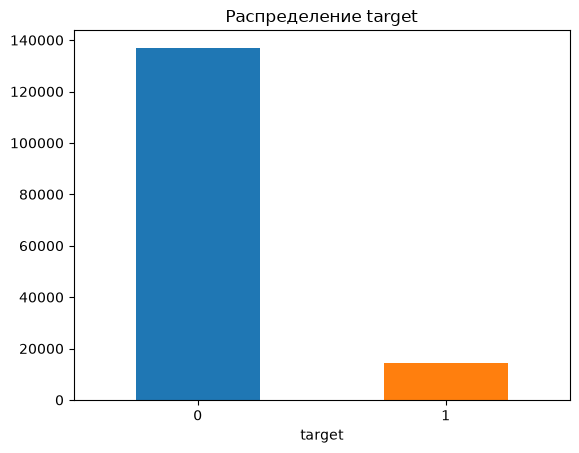

In [4]:
# Распределение целевой переменной
print(df['target'].value_counts())
print(df['target'].value_counts(normalize=True).round(4))

df['target'].value_counts().plot(kind='bar', color=['tab:blue', 'tab:orange'])
plt.title('Распределение target')
plt.xticks(rotation=0)
plt.show()

_Классы сильно несбалансированы: объектов класса 1 всего ≈ 9.5 %. Модель, которая всегда отвечает «0»,
уже получает accuracy ≈ 0.905, поэтому одной точности мало — дополнительно смотрим на precision, recall, F1 и ROC-AUC._

<h2>2. Предобработка</h2>

* `variable_3` — константа, `variable_15` — пропущена на 100 % → удаляем;
* у `variable_7` (63 % пропусков) и `variable_9` (89 %) пропуск сам по себе может нести информацию → добавляем бинарные признаки-индикаторы пропуска;
* остальные пропуски числовых признаков заполняем медианой (по обучающей выборке);
* категориальные признаки с небольшим числом значений (`variable_1, 5, 20, 28`) → one-hot кодирование;
* категориальные признаки с большим числом значений (`variable_21` — 192, `variable_22` — 1475) → частотное кодирование (доля объектов с этим значением);
* все признаки стандартизуем (среднее 0, стандартное отклонение 1) — для градиентного спуска это важно.

Все статистики (медианы, частоты, средние) считаются только по обучающей выборке, чтобы не было утечки данных из теста.

In [5]:
data = df.drop(columns=['variable_3', 'variable_15'])
y_all = data.pop('target').values

# train / validation / test = 64% / 16% / 20% со стратификацией по target
X_train_df, X_test_df, y_train, y_test = train_test_split(data, y_all, test_size=0.2,
                                                          stratify=y_all, random_state=42)
X_train_df, X_val_df, y_train, y_val = train_test_split(X_train_df, y_train, test_size=0.2,
                                                        stratify=y_train, random_state=42)
print(len(X_train_df), len(X_val_df), len(X_test_df))

96899 24225 30282


In [6]:
cat_low = ['variable_1', 'variable_5', 'variable_20', 'variable_28']   # one-hot
cat_high = ['variable_21', 'variable_22']                              # частотное кодирование
num_cols = [c for c in data.columns if c not in cat_low + cat_high]
nan_flag_cols = ['variable_7', 'variable_9']


class Preprocessor:
    def fit(self, X):
        self.medians = X[num_cols].median()
        self.freqs = {c: X[c].value_counts(normalize=True) for c in cat_high}
        Z = self._encode(X)
        self.columns = Z.columns
        self.mean = Z.mean()
        self.std = Z.std().replace(0, 1)
        return self

    def _encode(self, X):
        X = X.copy()
        for c in nan_flag_cols:
            X[c + '_nan'] = X[c].isna().astype(float)
        X[num_cols] = X[num_cols].fillna(self.medians)
        for c in cat_high:
            X[c] = X[c].map(self.freqs[c]).fillna(0)   # невиданное значение -> частота 0
        X = pd.get_dummies(X, columns=cat_low, dtype=float)
        if hasattr(self, 'columns'):
            X = X.reindex(columns=self.columns, fill_value=0)
        return X.astype(float)

    def transform(self, X):
        Z = (self._encode(X) - self.mean) / self.std
        return torch.tensor(Z.values, dtype=torch.float32)


prep = Preprocessor().fit(X_train_df)
X_train, X_val, X_test = (prep.transform(X_train_df), prep.transform(X_val_df), prep.transform(X_test_df))
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

n_features = X_train.shape[1]
print('Число признаков после кодирования:', n_features)
print(X_train.shape, X_val.shape, X_test.shape)

Число признаков после кодирования: 85
torch.Size([96899, 85]) torch.Size([24225, 85]) torch.Size([30282, 85])


In [7]:
# Вспомогательная функция для подсчёта метрик
def metrics(y_true, y_pred, y_score=None):
    res = {'accuracy': accuracy_score(y_true, y_pred),
           'precision': precision_score(y_true, y_pred, zero_division=0),
           'recall': recall_score(y_true, y_pred),
           'F1': f1_score(y_true, y_pred)}
    res['ROC-AUC'] = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    return res

results = {}
results['Константа «0» (baseline)'] = metrics(y_test, np.zeros_like(y_test))

<h2>3. Персептрон Розенблатта</h2>

Нейрон считает взвешенную сумму входов $s = \sum_i w_i x_i + b$ и пропускает её через ступенчатую функцию активации:

$$\hat y = \begin{cases} 1, & s > 0 \\ 0, & s \le 0 \end{cases}$$

Ступенька не дифференцируема, поэтому вместо градиентного спуска используется __правило обучения персептрона__:
объекты подаются по одному, и если персептрон ошибся, веса сдвигаются в сторону правильного ответа:

$$w \leftarrow w + \eta\,(y - \hat y)\,x, \qquad b \leftarrow b + \eta\,(y - \hat y)$$

Если классы линейно разделимы, алгоритм сходится за конечное число шагов. Если нет, веса так и будут «прыгать».

In [8]:
class Perceptron:
    def __init__(self, n_inputs):
        self.weights = torch.zeros(n_inputs)
        self.bias = torch.tensor(0.0)

    def net(self, inputs):
        return inputs @ self.weights + self.bias            # взвешенная сумма

    def forward(self, inputs):
        return (self.net(inputs) > 0).float()               # ступенчатая активация

    def train_epoch(self, X, y, lr):
        n_errors = 0
        for i in torch.randperm(len(X)):                    # объекты в случайном порядке
            x_i, y_i = X[i], y[i]
            error = y_i - self.forward(x_i)                 # 0, +1 или -1
            if error != 0:
                self.weights += lr * error * x_i
                self.bias += lr * error
                n_errors += 1
            # копим сумму весов после каждого шага — для усреднённого персептрона
            self.weights_sum += self.weights
            self.bias_sum += self.bias
            self.n_steps += 1
        return n_errors

    def start_averaging(self):
        self.weights_sum = torch.zeros_like(self.weights)
        self.bias_sum = torch.tensor(0.0)
        self.n_steps = 0

    def averaged(self):
        avg = Perceptron(len(self.weights))
        avg.weights = self.weights_sum / self.n_steps
        avg.bias = self.bias_sum / self.n_steps
        return avg

In [9]:
perceptron = Perceptron(n_features)
perceptron.start_averaging()
y_train_flat = y_train_t.view(-1)

errors = []
for epoch in range(10):
    n_err = perceptron.train_epoch(X_train, y_train_flat, lr=0.01)
    errors.append(n_err)
    val_acc = accuracy_score(y_val, perceptron.forward(X_val).numpy())
    print(f'epoch {epoch}  ошибок за эпоху {n_err} ({n_err / len(X_train):.3f})  val accuracy {val_acc:.4f}')

epoch 0  ошибок за эпоху 15462 (0.160)  val accuracy 0.8716
epoch 1  ошибок за эпоху 15440 (0.159)  val accuracy 0.8605
epoch 2  ошибок за эпоху 15386 (0.159)  val accuracy 0.8798
epoch 3  ошибок за эпоху 15317 (0.158)  val accuracy 0.7715
epoch 4  ошибок за эпоху 15321 (0.158)  val accuracy 0.8854
epoch 5  ошибок за эпоху 15313 (0.158)  val accuracy 0.8607
epoch 6  ошибок за эпоху 15403 (0.159)  val accuracy 0.8238
epoch 7  ошибок за эпоху 15328 (0.158)  val accuracy 0.8537
epoch 8  ошибок за эпоху 15446 (0.159)  val accuracy 0.8691
epoch 9  ошибок за эпоху 15390 (0.159)  val accuracy 0.8575


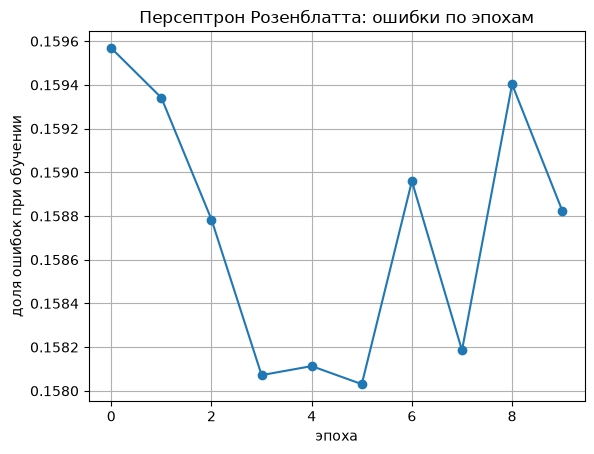

In [10]:
plt.plot(np.array(errors) / len(X_train), marker='o')
plt.xlabel('эпоха')
plt.ylabel('доля ошибок при обучении')
plt.title('Персептрон Розенблатта: ошибки по эпохам')
plt.grid(True)
plt.show()

_Доля ошибок не уменьшается от эпохи к эпохе: выборка __линейно неразделима__, поэтому правило персептрона не сходится,
веса всё время колеблются. Итоговое качество зависит от того, на каком объекте остановились._

Стандартный способ сгладить эти колебания — __усреднённый персептрон__: в качестве итоговых берутся
веса, усреднённые по всем шагам обучения (мы копили их сумму в `train_epoch`).

In [11]:
avg_perceptron = perceptron.averaged()

pred_test = perceptron.forward(X_test).numpy()
score_test = perceptron.net(X_test).numpy()
results['Персептрон Розенблатта (последние веса)'] = metrics(y_test, pred_test, score_test)

pred_test_avg = avg_perceptron.forward(X_test).numpy()
score_test_avg = avg_perceptron.net(X_test).numpy()
results['Персептрон Розенблатта (усреднённые веса)'] = metrics(y_test, pred_test_avg, score_test_avg)

pd.DataFrame(results).T.round(4)

,accuracy,precision,recall,F1,ROC-AUC
Константа «0» (baseline),0.9045,0.0000,0.0000,0.0000,NaN
Персептрон Розенблатта (последние веса),0.8548,0.1255,0.0871,0.1029,0.4807
Персептрон Розенблатта (усреднённые веса),0.9099,0.6633,0.1145,0.1952,0.5978


<h2>4. Персептрон с сигмоидой (один нейрон + SGD)</h2>

Заменим ступеньку на гладкую __сигмоиду__, тогда выход нейрона можно трактовать как вероятность класса 1
и обучать его градиентным спуском:

$$\hat y = \sigma(s) = \frac{1}{1 + e^{-s}}, \qquad s = Xw + b$$

Для бинарной классификации вместо MSE берём __бинарную кроссэнтропию__ (Binary Cross-Entropy):

$$L = -\frac{1}{N}\sum_{k=1}^{N}\Big(y_k \log \hat y_k + (1 - y_k)\log(1 - \hat y_k)\Big)$$

Цепочка производных для обратного прохода (как на графе вычислений из занятия):

$$\frac{\partial L}{\partial \hat y_k} = \frac{1}{N}\left(-\frac{y_k}{\hat y_k} + \frac{1 - y_k}{1 - \hat y_k}\right), \qquad
\frac{\partial \hat y}{\partial s} = \sigma(s)\,(1 - \sigma(s)), \qquad
\nabla_w L = X^T \frac{\partial L}{\partial s}, \qquad \nabla_b L = \sum_k \frac{\partial L}{\partial s_k}$$

In [12]:
class Dense:
    def __init__(self, n_inputs, n_neurons):
        self.weights = 0.01 * torch.randn(n_inputs, n_neurons, requires_grad=False)
        self.biases = torch.zeros(n_neurons, requires_grad=False)

    def forward(self, inputs):
        self.inputs = inputs
        self.output = self.inputs @ self.weights + self.biases
        return self.output

    def backward(self, dvalues):
        with torch.no_grad():
            self.dweights = self.inputs.T @ dvalues
            self.dbiases = torch.sum(dvalues, dim=0)
            self.dinputs = dvalues @ self.weights.T


class Activation_Sigmoid:
    def forward(self, inputs):
        self.inputs = inputs
        self.output = 1 / (1 + torch.exp(-inputs))
        return self.output

    def backward(self, dvalues):
        with torch.no_grad():
            self.dinputs = dvalues * self.output * (1 - self.output)


class Loss:
    def calculate(self, output, y):
        sample_losses = self.forward(output, y)
        data_loss = sample_losses.mean()
        return data_loss


class BinaryCrossentropyLoss(Loss):
    eps = 1e-7    # чтобы не брать log(0)

    def forward(self, y_pred, y_true):
        y_pred = y_pred.clamp(self.eps, 1 - self.eps)
        sample_losses = -(y_true * torch.log(y_pred) + (1 - y_true) * torch.log(1 - y_pred))
        return sample_losses.view(-1)

    def backward(self, dvalues, y_true):
        with torch.no_grad():
            dvalues = dvalues.clamp(self.eps, 1 - self.eps)
            self.dinputs = (-(y_true / dvalues) + (1 - y_true) / (1 - dvalues)) / len(dvalues)

Проверим, что ручной `backward` считает градиенты правильно: сравним их с автоматическим дифференцированием Torch (`autograd`) на одном пакете.

In [13]:
fc_check = Dense(n_features, 1)
sigm_check = Activation_Sigmoid()
loss_check = BinaryCrossentropyLoss()

xb, yb = X_train[:256], y_train_t[:256]
out = sigm_check.forward(fc_check.forward(xb))
loss_check.backward(out, yb)
sigm_check.backward(loss_check.dinputs)
fc_check.backward(sigm_check.dinputs)

# то же самое через autograd
w = fc_check.weights.clone().requires_grad_(True)
b = fc_check.biases.clone().requires_grad_(True)
torch.nn.functional.binary_cross_entropy(torch.sigmoid(xb @ w + b), yb).backward()

print('max |dW_ручной - dW_autograd| =', (fc_check.dweights - w.grad).abs().max().item())
print('max |db_ручной - db_autograd| =', (fc_check.dbiases - b.grad).abs().max().item())

max |dW_ручной - dW_autograd| = 1.1175870895385742e-08
max |db_ручной - db_autograd| = 0.0


Обучение мини-пакетным SGD: на каждой эпохе перемешиваем обучающую выборку, режем её на пакеты по 256 объектов и
на каждом пакете делаем прямой проход → потери → обратный проход → шаг градиентного спуска.

In [14]:
torch.manual_seed(42)
fc1 = Dense(n_features, 1)
sigmoid1 = Activation_Sigmoid()
loss = BinaryCrossentropyLoss()

lr = 0.1
batch_size = 256
n_epochs = 30

train_losses, val_losses = [], []
for epoch in range(n_epochs):
    idx = torch.randperm(len(X_train))
    for start in range(0, len(X_train), batch_size):
        batch = idx[start:start + batch_size]
        xb, yb = X_train[batch], y_train_t[batch]

        out = fc1.forward(xb)
        out = sigmoid1.forward(out)

        loss.backward(out, yb)
        sigmoid1.backward(loss.dinputs)
        fc1.backward(sigmoid1.dinputs)

        fc1.weights -= lr * fc1.dweights
        fc1.biases -= lr * fc1.dbiases

    # потери на всей обучающей и валидационной выборке в конце эпохи
    train_loss = loss.calculate(sigmoid1.forward(fc1.forward(X_train)), y_train_t).item()
    val_loss = loss.calculate(sigmoid1.forward(fc1.forward(X_val)), y_val_t).item()
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    if epoch % 5 == 0 or epoch == n_epochs - 1:
        print(f'epoch {epoch}  train loss {train_loss:.5f}  val loss {val_loss:.5f}')

epoch 0  train loss 0.29042  val loss 0.28860
epoch 5  train loss 0.28987  val loss 0.28879
epoch 10  train loss 0.28993  val loss 0.28816
epoch 15  train loss 0.28976  val loss 0.28847
epoch 20  train loss 0.28976  val loss 0.28829
epoch 25  train loss 0.28986  val loss 0.28845
epoch 29  train loss 0.28994  val loss 0.28844


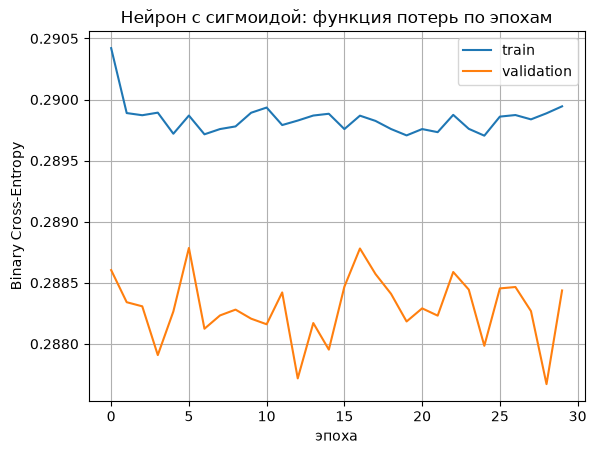

In [15]:
plt.plot(train_losses, label='train')
plt.plot(val_losses, label='validation')
plt.xlabel('эпоха')
plt.ylabel('Binary Cross-Entropy')
plt.title('Нейрон с сигмоидой: функция потерь по эпохам')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
def predict_proba(X):
    return sigmoid1.forward(fc1.forward(X)).view(-1).numpy()

proba_val = predict_proba(X_val)
proba_test = predict_proba(X_test)

results['Нейрон с сигмоидой, порог 0.5'] = metrics(y_test, (proba_test > 0.5).astype(int), proba_test)
pd.Series(results['Нейрон с сигмоидой, порог 0.5']).round(4)

accuracy     0.9124
precision    0.7691
recall       0.1186
F1           0.2055
ROC-AUC      0.6615
dtype: float64

<h3>Подбор порога классификации</h3>

При пороге 0.5 модель почти всегда отвечает «0» (класс 1 редкий), и recall получается низким.
Подберём порог, максимизирующий F1, на __валидационной__ выборке. Тестовая выборка в подборе не участвует.

Лучший порог по F1 на валидации: 0.12  (F1 = 0.2632)


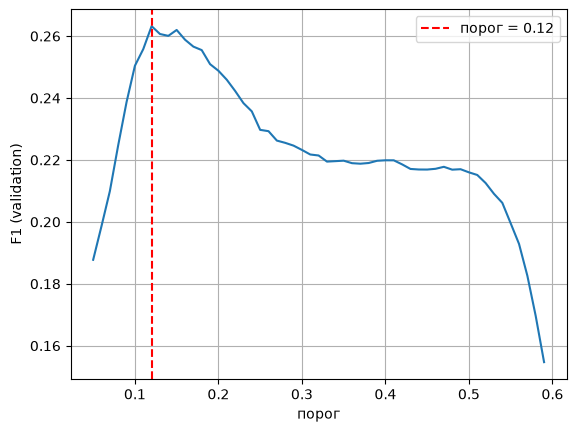

In [17]:
thresholds = np.arange(0.05, 0.6, 0.01)
f1_val = [f1_score(y_val, (proba_val > t).astype(int)) for t in thresholds]
best_t = thresholds[int(np.argmax(f1_val))]
print(f'Лучший порог по F1 на валидации: {best_t:.2f}  (F1 = {max(f1_val):.4f})')

plt.plot(thresholds, f1_val)
plt.axvline(best_t, color='r', linestyle='--', label=f'порог = {best_t:.2f}')
plt.xlabel('порог')
plt.ylabel('F1 (validation)')
plt.legend()
plt.grid(True)
plt.show()

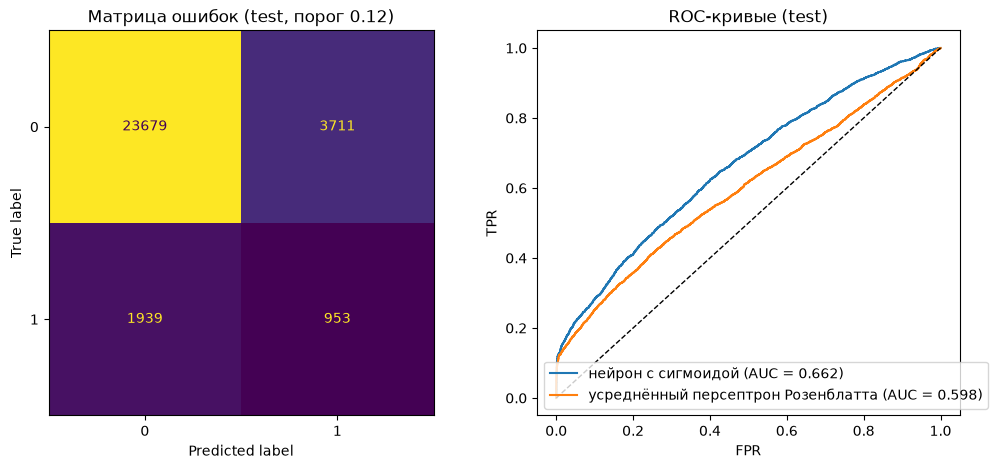

In [18]:
pred_best = (proba_test > best_t).astype(int)
results[f'Нейрон с сигмоидой, порог {best_t:.2f}'] = metrics(y_test, pred_best, proba_test)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_best)).plot(ax=axs[0], colorbar=False)
axs[0].set_title(f'Матрица ошибок (test, порог {best_t:.2f})')

fpr, tpr, _ = roc_curve(y_test, proba_test)
axs[1].plot(fpr, tpr, label=f'нейрон с сигмоидой (AUC = {roc_auc_score(y_test, proba_test):.3f})')
fpr_p, tpr_p, _ = roc_curve(y_test, score_test_avg)
axs[1].plot(fpr_p, tpr_p, label=f'усреднённый персептрон Розенблатта (AUC = {roc_auc_score(y_test, score_test_avg):.3f})')
axs[1].plot([0, 1], [0, 1], 'k--', lw=1)
axs[1].set_xlabel('FPR')
axs[1].set_ylabel('TPR')
axs[1].set_title('ROC-кривые (test)')
axs[1].legend()
plt.show()

<h2>5. Тот же персептрон средствами torch.nn</h2>

Для проверки соберём ту же модель из готовых блоков Torch: `nn.Linear(n, 1)` + `BCEWithLogitsLoss`
(сигмоида внутри функции потерь) + оптимизатор `torch.optim.SGD`. Градиенты здесь считает `autograd`.

In [19]:
torch.manual_seed(42)
model = torch.nn.Linear(n_features, 1)
criterion = torch.nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

for epoch in range(n_epochs):
    idx = torch.randperm(len(X_train))
    for start in range(0, len(X_train), batch_size):
        batch = idx[start:start + batch_size]
        optimizer.zero_grad()
        l = criterion(model(X_train[batch]), y_train_t[batch])
        l.backward()
        optimizer.step()
    if epoch % 10 == 0 or epoch == n_epochs - 1:
        with torch.no_grad():
            print(f'epoch {epoch}  val loss {criterion(model(X_val), y_val_t).item():.5f}')

with torch.no_grad():
    proba_test_nn = torch.sigmoid(model(X_test)).view(-1).numpy()
results[f'torch.nn: Linear + сигмоида, порог {best_t:.2f}'] = metrics(y_test, (proba_test_nn > best_t).astype(int), proba_test_nn)

epoch 0  val loss 0.28876
epoch 10  val loss 0.28796
epoch 20  val loss 0.28857
epoch 29  val loss 0.28791


<h2>6. Сравнение результатов на тестовой выборке</h2>

In [20]:
pd.DataFrame(results).T.round(4)

,accuracy,precision,recall,F1,ROC-AUC
Константа «0» (baseline),0.9045,0.0000,0.0000,0.0000,NaN
Персептрон Розенблатта (последние веса),0.8548,0.1255,0.0871,0.1029,0.4807
Персептрон Розенблатта (усреднённые веса),0.9099,0.6633,0.1145,0.1952,0.5978
"Нейрон с сигмоидой, порог 0.5",0.9124,0.7691,0.1186,0.2055,0.6615
"Нейрон с сигмоидой, порог 0.12",0.8134,0.2043,0.3295,0.2522,0.6615
"torch.nn: Linear + сигмоида, порог 0.12",0.8132,0.2078,0.3399,0.2579,0.6634


<h3>Какие признаки важнее всего для нейрона</h3>

Признаки стандартизованы, поэтому модуль веса показывает, насколько сильно признак влияет на выход нейрона.

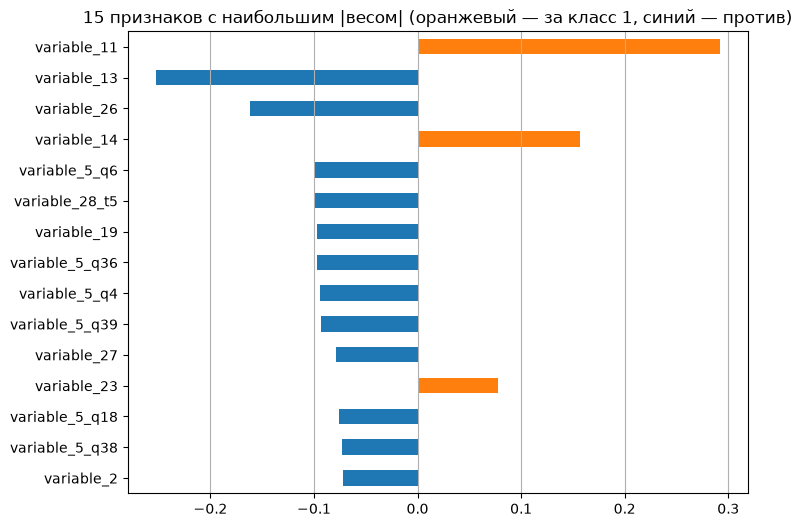

In [21]:
weights = pd.Series(fc1.weights.view(-1).numpy(), index=prep.columns)
top = weights.reindex(weights.abs().sort_values(ascending=False).index)[:15][::-1]
top.plot(kind='barh', color=np.where(top > 0, 'tab:orange', 'tab:blue'), figsize=(8, 6))
plt.title('15 признаков с наибольшим |весом| (оранжевый — за класс 1, синий — против)')
plt.grid(True, axis='x')
plt.show()